In [2]:
###IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('/content/data.csv', encoding='ISO-8859-1')

In [3]:
### INITIAL DATA EXPLORATION
display(df.head())
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nDataset Information:")
df.info()
display(df.describe(include='all'))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


Dataset Shape: (541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900,4070,4223,NaN,23260,NaN,NaN,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,10/31/2011 14:41,NaN,NaN,United Kingdom
freq,1114,2313,2369,NaN,1114,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,NaN,4.611114,15287.690570,NaN
std,NaN,NaN,NaN,218.081158,NaN,96.759853,1713.600303,NaN
min,NaN,NaN,NaN,-80995.000000,NaN,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,NaN,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,NaN,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,NaN,4.130000,16791.000000,NaN


In [4]:
### DATA CLEANING AND PREPROCESSING
print("Missing Values:")
print(df.isnull().sum())
print("\nDuplicate Records:", df.duplicated().sum())
df.drop_duplicates(inplace=True)
df.dropna(subset=['CustomerID', 'InvoiceDate'], inplace=True)
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
print("\nCleaned Dataset Shape:", df.shape)
print("\nRemaining Missing Values:")
print(df.isnull().sum())

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Records: 5268

Cleaned Dataset Shape: (392692, 8)

Remaining Missing Values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


Total Revenue: 8887208.894000001
Total Transactions: 18532
Total Customers: 4338


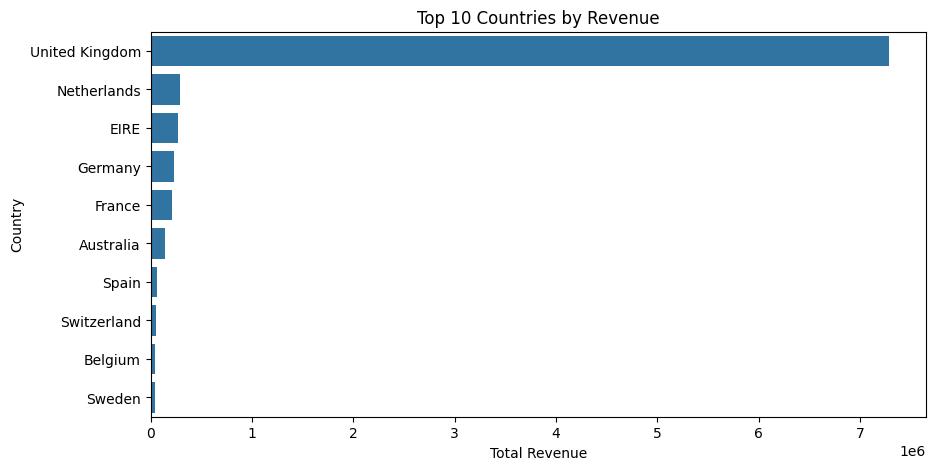

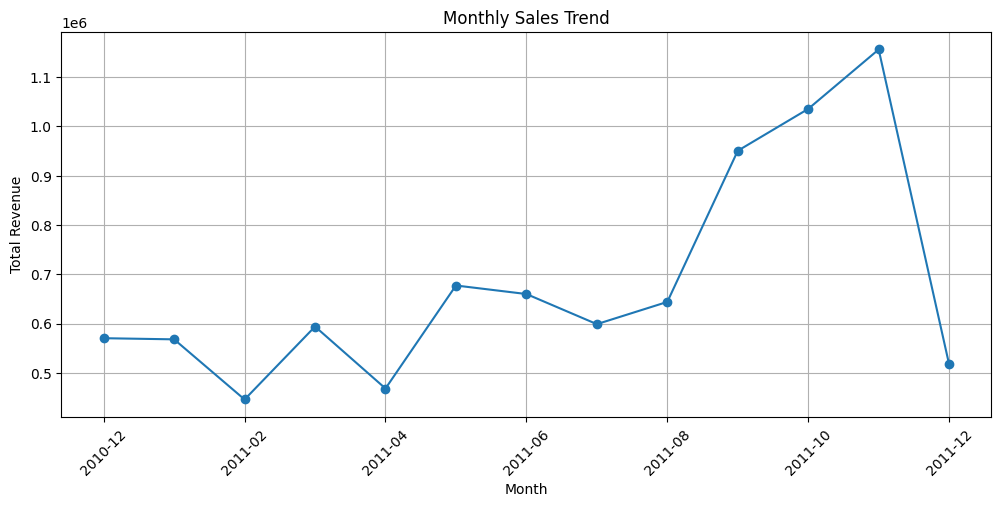

In [5]:
### EXPLORATORY DATA ANALYSIS
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']
print("Total Revenue:", df['TotalPrice'].sum())
print("Total Transactions:", df['InvoiceNo'].nunique())
print("Total Customers:", df['CustomerID'].nunique())
country_sales = df.groupby('Country')['TotalPrice'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 5))
sns.barplot(x=country_sales.values, y=country_sales.index)
plt.title('Top 10 Countries by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Country')
plt.show()
df['Month'] = df['InvoiceDate'].dt.to_period('M').astype(str)
monthly_sales = df.groupby('Month')['TotalPrice'].sum()
plt.figure(figsize=(12, 5))
monthly_sales.plot(kind='line', marker='o')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [7]:
### DESCRIPTIVE STATISTICS
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']
average_purchase_value = df.groupby('InvoiceNo')['TotalPrice'].sum().mean()
purchase_frequency = df.groupby('CustomerID')['InvoiceNo'].nunique().mean()
customer_lifetime_value = df.groupby('CustomerID')['TotalPrice'].sum()
print("Average Purchase Value:", round(average_purchase_value, 2))
print("Average Purchase Frequency:", round(purchase_frequency, 2))
print("Average Customer Lifetime Value:", round(customer_lifetime_value.mean(), 2))

Average Purchase Value: 479.56
Average Purchase Frequency: 4.27
Average Customer Lifetime Value: 2048.69


In [8]:
### RFM ANALYSIS
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalPrice': 'sum'
})
rfm.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalPrice': 'Monetary'
}, inplace=True)
print("RFM Analysis Results:")
display(rfm.head())
display(rfm.describe())

RFM Analysis Results:


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [9]:
### FEATURE SELECTION
rfm_features = rfm[['Recency', 'Frequency', 'Monetary']]
print("Selected Features:")
display(rfm_features.head())
print("Feature Shape:", rfm_features.shape)

Selected Features:


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


Feature Shape: (4338, 3)


In [10]:
### DATA STANDARDIZATION
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_features)
rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=['Recency', 'Frequency', 'Monetary'],
    index=rfm_features.index
)
print("Standardized RFM Features:")
display(rfm_scaled.head())
display(rfm_scaled.describe().round(2))

Standardized RFM Features:


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,2.334574,-0.425097,8.363010
12347.0,-0.905340,0.354417,0.251699
12348.0,-0.175360,-0.035340,-0.027988
12349.0,-0.735345,-0.425097,-0.032406
12350.0,2.174578,-0.425097,-0.190812


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,0.00,0.00,0.00
std,1.00,1.00,1.00
min,-0.92,-0.43,-0.23
25%,-0.75,-0.43,-0.19
50%,-0.42,-0.30,-0.15
75%,0.49,0.09,-0.04
max,2.81,26.60,30.96


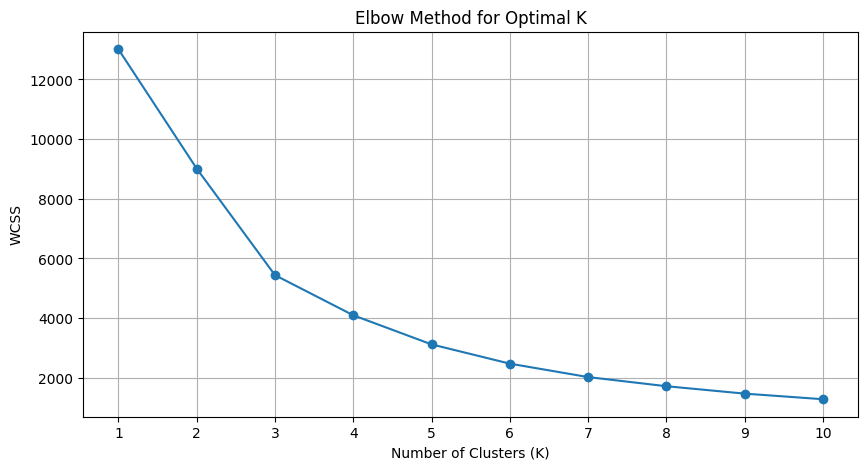

In [11]:
### ELBOW METHOD
from sklearn.cluster import KMeans
wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)
plt.figure(figsize=(10, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [12]:
### APPLY K-MEANS CLUSTERING
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)
print("Customer Segmentation Results:")
display(rfm.head(10))
print("\nNumber of Customers in Each Cluster:")
print(rfm['Cluster'].value_counts().sort_index())

Customer Segmentation Results:


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346.0,326,1,77183.60,0
12347.0,2,7,4310.00,1
12348.0,75,4,1797.24,1
12349.0,19,1,1757.55,1
12350.0,310,1,334.40,0
12352.0,36,8,2506.04,1
12353.0,204,1,89.00,0
12354.0,232,1,1079.40,0
12355.0,214,1,459.40,0



Number of Customers in Each Cluster:
Cluster
0    1082
1    3230
2      26
Name: count, dtype: int64


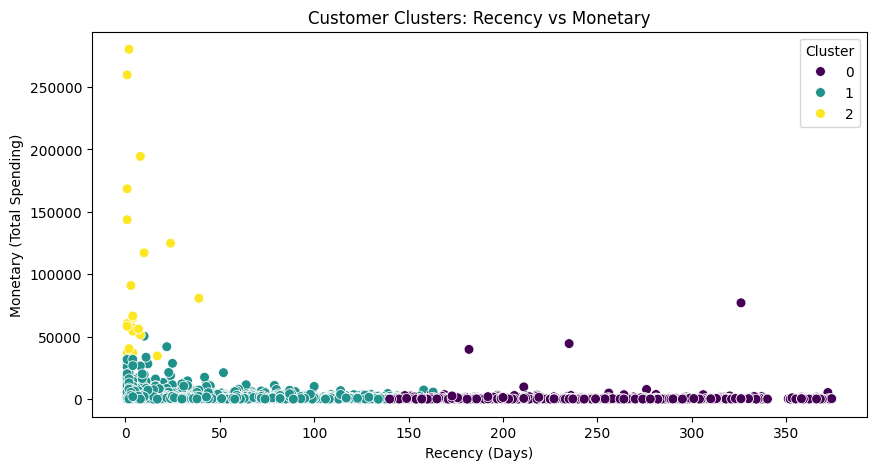

In [13]:
### VISUALIZE CUSTOMER CLUSTERS
# Scatter Plot 1: Recency vs Monetary
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    s=50
)
plt.title('Customer Clusters: Recency vs Monetary')
plt.xlabel('Recency (Days)')
plt.ylabel('Monetary (Total Spending)')
plt.legend(title='Cluster')
plt.show()

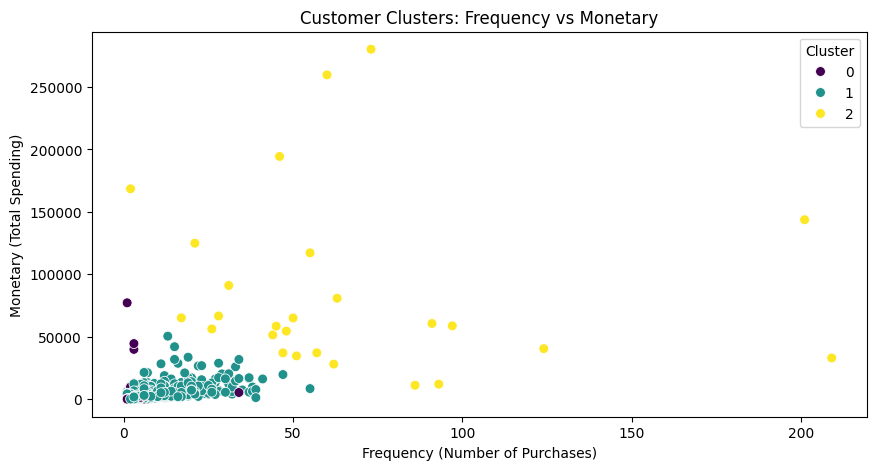

In [14]:
# Scatter Plot 2: Frequency vs Monetary
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    s=50
)
plt.title('Customer Clusters: Frequency vs Monetary')
plt.xlabel('Frequency (Number of Purchases)')
plt.ylabel('Monetary (Total Spending)')
plt.legend(title='Cluster')
plt.show()

In [16]:
### CUSTOMER SEGMENT PROFILING
cluster_profile = rfm.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean().round(2)
cluster_profile['Customer_Count'] = rfm.groupby('Cluster').size()
print("Customer Segment Profiles:")
display(cluster_profile)
customer_types = {
    0: "At-Risk / Inactive Customers",
    1: "Regular Customers",
    2: "High-Value / VIP Customers"
}
rfm['Customer_Type'] = rfm['Cluster'].map(customer_types)
print("Customer Segment Descriptions:")
display(rfm[['Recency', 'Frequency', 'Monetary', 'Cluster', 'Customer_Type']].head(10))

Customer Segment Profiles:


,Recency,Frequency,Monetary,Customer_Count
Cluster,,,,
0,247.11,1.58,629.66,1082
1,41.45,4.67,1849.67,3230
2,6.04,66.42,85826.08,26


Customer Segment Descriptions:


,Recency,Frequency,Monetary,Cluster,Customer_Type
CustomerID,,,,,
12346.0,326,1,77183.60,0,At-Risk / Inactive Customers
12347.0,2,7,4310.00,1,Regular Customers
12348.0,75,4,1797.24,1,Regular Customers
12349.0,19,1,1757.55,1,Regular Customers
12350.0,310,1,334.40,0,At-Risk / Inactive Customers
12352.0,36,8,2506.04,1,Regular Customers
12353.0,204,1,89.00,0,At-Risk / Inactive Customers
12354.0,232,1,1079.40,0,At-Risk / Inactive Customers
12355.0,214,1,459.40,0,At-Risk / Inactive Customers


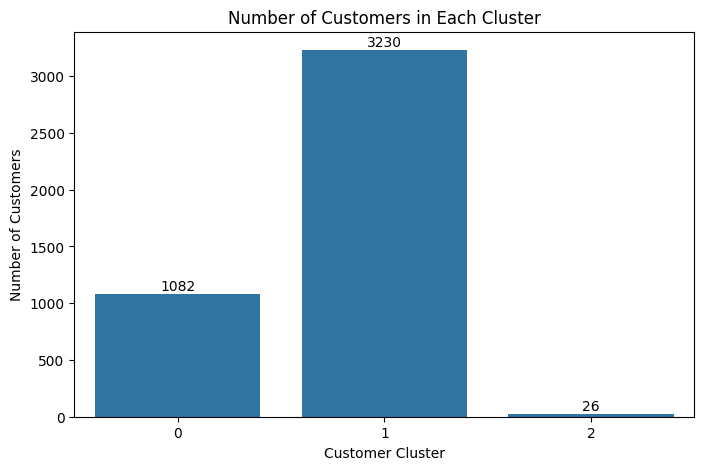

In [17]:
### CUSTOMER DISTRIBUTION ANALYSIS
cluster_counts = rfm['Cluster'].value_counts().sort_index()
plt.figure(figsize=(8, 5))
sns.barplot(x=cluster_counts.index, y=cluster_counts.values)
plt.title('Number of Customers in Each Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')
for i, value in enumerate(cluster_counts.values):
    plt.text(i, value + 30, str(value), ha='center')

plt.show()

### INSIGHTS AND MARKETING RECOMMENDATIONS

- **Cluster 0 – At-Risk Customers:** These customers purchase less frequently. Offer special discounts and promotional emails to encourage them to return.

- **Cluster 1 – Regular Customers:** These customers purchase regularly. Introduce loyalty programs and personalized offers to increase their purchases.

- **Cluster 2 – High-Value Customers:** These customers purchase frequently and spend more. Provide VIP rewards, exclusive discounts and early access to new products.

**Overall Insight:** The company should focus on retaining high-value customers, encouraging regular customers to spend more and re-engaging inactive customers.